# Unemployment Analysis with Python
## OASIS INFOBYTE – Data Science Internship | Task 2

### Project objective
Analyze unemployment patterns in India using exploratory data analysis (EDA). The notebook examines regional averages, monthly trends, selected-region comparisons, correlations among labour indicators, and a descriptive pre-COVID/post-COVID comparison.

### Dataset
- **File:** `Unemployment in India.csv`
- **Expected columns:** Region, Date, Frequency, Estimated Unemployment Rate (%), Estimated Employed, Estimated Labour Participation Rate (%), Area
- **Important:** Keep the CSV file in the same folder as this notebook, or update the file path in the data-loading cell.

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn, Jupyter Notebook.

### Analysis workflow
1. Import libraries and load the dataset.
2. Inspect, clean, and validate the data.
3. Explore region-wise and month-wise unemployment.
4. Compare at least three regions over time.
5. Identify the ten regions with the highest average unemployment.
6. Examine correlations among the available labour indicators.
7. Compare observations before and after March 2020.
8. Summarize findings and limitations.

> **Interpretation note:** This is an exploratory analysis of the supplied dataset. Correlation does not establish causation, and the pre/post-2020 comparison alone cannot prove that COVID-19 caused a change in unemployment.


## 1. Import libraries

In [13]:
# Install these packages only if they are not already available in your environment.
# In a Jupyter environment, run this cell once if imports fail.
%pip install pandas numpy matplotlib seaborn

All libraries imported successfully!


In [14]:
# Load the CSV file.
# Keep "Unemployment in India.csv" in the same folder as this notebook.
from pathlib import Path

csv_path = Path("Unemployment in India.csv")

if not csv_path.exists():
    raise FileNotFoundError(
        "CSV file not found. Place 'Unemployment in India.csv' "
        "in the same folder as this notebook, or update csv_path."
    )

df = pd.read_csv(csv_path)

print("Dataset loaded successfully.")
display(df.head())

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 2. Load and inspect the dataset
Check the dataset dimensions, column names, data types, and descriptive statistics.

In [15]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()

Dataset shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    str    
 1    Date                                     740 non-null    str    
 2    Frequency                                740 non-null    str    
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    str    
dtypes: float64(3), str(4)
memory usage: 30.1 KB


## 3. Clean column names and inspect data quality

In [16]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)
print("Cleaned column names:")
print(df.columns.tolist())
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))
print("\nDuplicate rows:", df.duplicated().sum())

Cleaned column names:
['region', 'date', 'frequency', 'estimated_unemployment_rate', 'estimated_employed', 'estimated_labour_participation_rate', 'area']

Missing values:


,Missing Values
region,28
date,28
frequency,28
estimated_unemployment_rate,28
estimated_employed,28
estimated_labour_participation_rate,28
area,28



Duplicate rows: 27


## 4. Convert data types

In [17]:
if "date" in df.columns:
    df["date"] = pd.to_datetime(
        df["date"].astype(str).str.strip(),
        errors="coerce",
        dayfirst=True
    )
for col in [
    "estimated_unemployment_rate",
    "estimated_employed",
    "estimated_labour_participation_rate"
]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Updated data types:")
print(df.dtypes)
print("\nMissing values after conversion:")
display(df.isnull().sum().to_frame("Missing Values"))

Updated data types:
region                                            str
date                                   datetime64[us]
frequency                                         str
estimated_unemployment_rate                   float64
estimated_employed                            float64
estimated_labour_participation_rate           float64
area                                              str
dtype: object

Missing values after conversion:


,Missing Values
region,28
date,28
frequency,28
estimated_unemployment_rate,28
estimated_employed,28
estimated_labour_participation_rate,28
area,28


## 5. Validate required columns and prepare the analysis dataset
The cleaning step removes duplicate rows, records missing essential fields, and unemployment rates outside the 0–100% range.

In [18]:
required_columns = [
    "region",
    "date",
    "estimated_unemployment_rate",
    "estimated_employed",
    "estimated_labour_participation_rate"
]
missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(
        f"Required columns not found: {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )
analysis_df = df.drop_duplicates().copy()
analysis_df = analysis_df.dropna(
    subset=[
        "region",
        "date",
        "estimated_unemployment_rate"
    ]
)
analysis_df = analysis_df[
    analysis_df["estimated_unemployment_rate"].between(0, 100)
].copy()

analysis_df["month"] = (
    analysis_df["date"].dt.to_period("M").dt.to_timestamp()
)

print("Original dataset shape:", df.shape)
print("Analysis dataset shape:", analysis_df.shape)
print("Date range:",
      analysis_df["date"].min(),
      "to",
      analysis_df["date"].max())


Original dataset shape: (768, 7)
Analysis dataset shape: (740, 8)
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


## 6. Region-wise average unemployment rate

In [19]:

# Calculate average unemployment rate by region

region_avg = (
    analysis_df.groupby("region")["estimated_unemployment_rate"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Unemployment Rate by Region:")
display(region_avg.round(2))


Average Unemployment Rate by Region:


region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Punjab              12.03
Puducherry          10.22
Kerala              10.12
Tamil Nadu           9.28
Goa                  9.27
Chhattisgarh         9.24
West Bengal          8.12
Telangana            7.74
Maharashtra          7.56
Andhra Pradesh       7.48
Madhya Pradesh       7.41
Sikkim               7.25
Karnataka            6.68
Gujarat              6.66
Uttarakhand          6.58
Assam                6.43
Odisha               5.66
Meghalaya            4.80
Name: estimated_unemployment_rate, dtype: float64

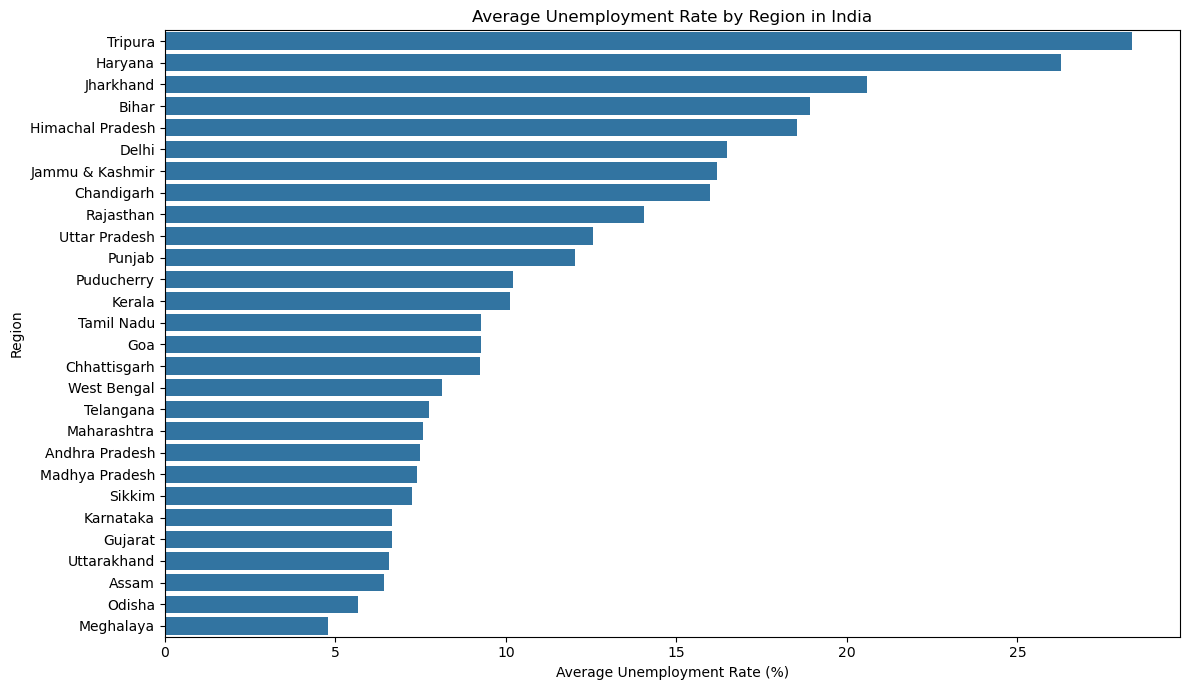

In [20]:

# Bar chart of regional unemployment rates

plt.figure(figsize=(12, 7))

sns.barplot(
    x=region_avg.values,
    y=region_avg.index
)

plt.title("Average Unemployment Rate by Region in India")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()


### Interpretation – regional averages
After running the chart, record:
- The region with the highest average unemployment rate.
- The region with the lowest average unemployment rate.
- Any notable differences between regions.

Use the values produced by your notebook; do not guess the findings.

In [21]:

# Calculate monthly average unemployment rate

monthly_avg = (
    analysis_df.groupby("month")["estimated_unemployment_rate"]
    .mean()
)

display(monthly_avg.round(2))


month
2019-05-01     8.87
2019-06-01     9.30
2019-07-01     9.03
2019-08-01     9.64
2019-09-01     9.05
2019-10-01     9.90
2019-11-01     9.87
2019-12-01     9.50
2020-01-01     9.95
2020-02-01     9.96
2020-03-01    10.70
2020-04-01    23.64
2020-05-01    24.88
2020-06-01    11.90
Name: estimated_unemployment_rate, dtype: float64

## 7. Month-wise unemployment trend

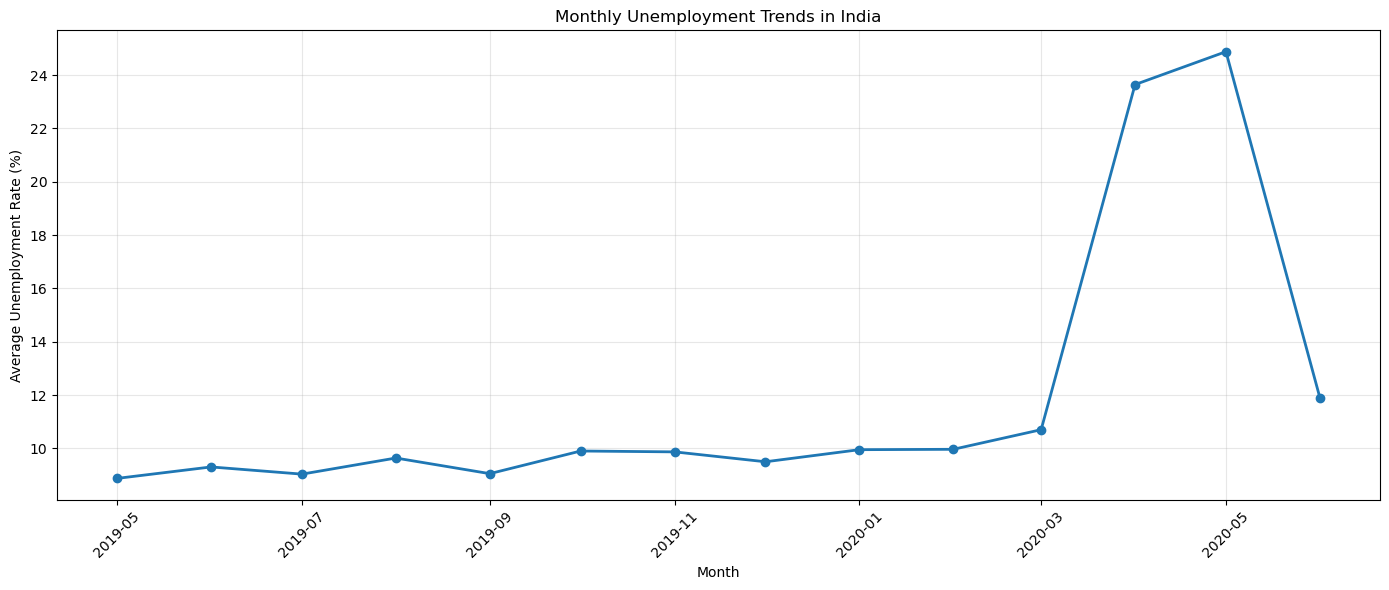

In [22]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Unemployment Trends in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [23]:
# Select three regions with the greatest number of valid observations.
# This makes the selection reproducible and ensures adequate data coverage;
# it does not claim these are India's three largest states.
region_counts = analysis_df["region"].value_counts()
selected_regions = region_counts.head(3).index.tolist()

if len(selected_regions) < 3:
    raise ValueError("At least three regions are required for this comparison.")

print("Selected regions (based on valid observation counts):", selected_regions)

# Calculate monthly unemployment rates for the selected regions.
region_monthly = (
    analysis_df[analysis_df["region"].isin(selected_regions)]
    .groupby(["month", "region"])["estimated_unemployment_rate"]
    .mean()
    .reset_index()
)

display(region_monthly.head())

Selected regions: ['Andhra Pradesh', 'Bihar', 'Chhattisgarh']


,month,region,estimated_unemployment_rate
0,2019-05-01,Andhra Pradesh,4.870
1,2019-05-01,Bihar,14.585
2,2019-05-01,Chhattisgarh,9.795
3,2019-06-01,Andhra Pradesh,3.425
4,2019-06-01,Bihar,11.745


### Interpretation – monthly trend
After viewing the line chart, identify the month with the highest and lowest average rate and describe any visible rises or falls. Mention that the monthly average is calculated across all available region/area observations.

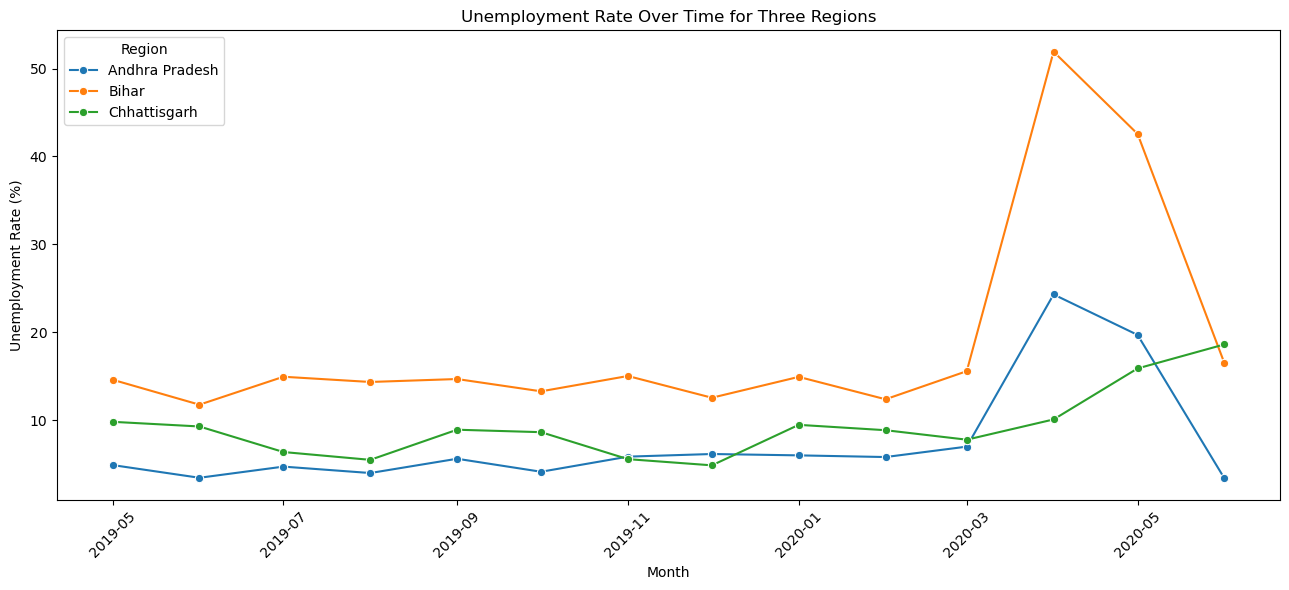

In [24]:

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=region_monthly,
    x="month",
    y="estimated_unemployment_rate",
    hue="region",
    marker="o"
)

plt.title("Unemployment Rate Over Time for Three Regions")
plt.xlabel("Month")
plt.ylabel("Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.legend(title="Region")

plt.tight_layout()
plt.show()


## 8. Compare unemployment trends across three regions

In [25]:

top10_regions = region_avg.head(10)

display(top10_regions.round(2))


region
Tripura             28.35
Haryana             26.28
Jharkhand           20.58
Bihar               18.92
Himachal Pradesh    18.54
Delhi               16.50
Jammu & Kashmir     16.19
Chandigarh          15.99
Rajasthan           14.06
Uttar Pradesh       12.55
Name: estimated_unemployment_rate, dtype: float64

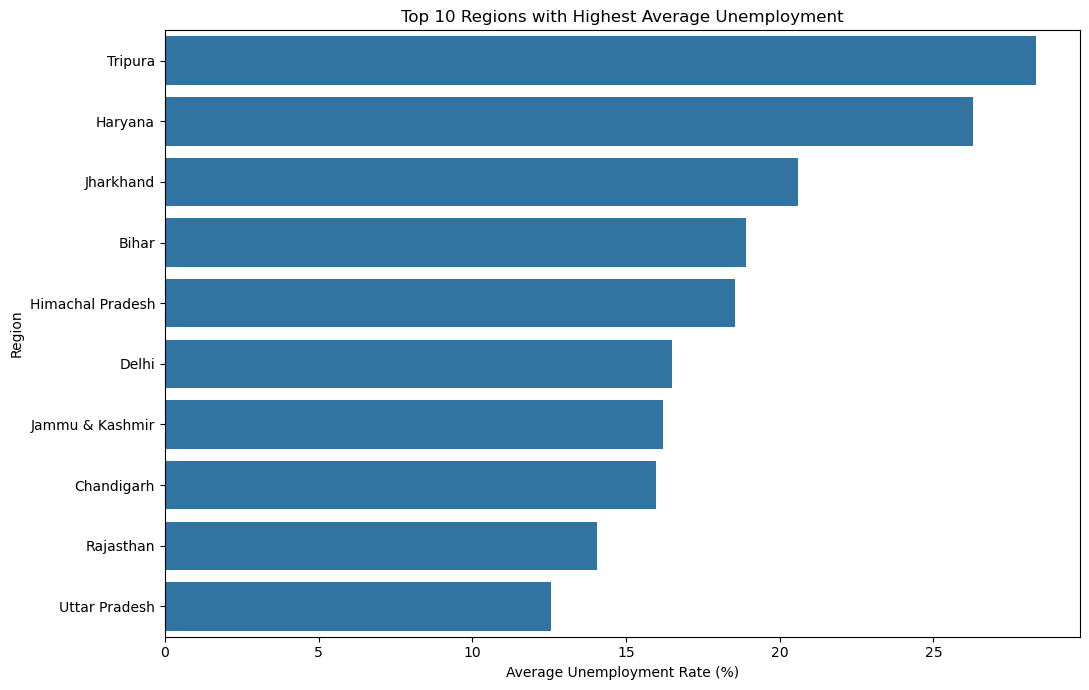

In [26]:

plt.figure(figsize=(11, 7))

sns.barplot(
    x=top10_regions.values,
    y=top10_regions.index
)

plt.title("Top 10 Regions with Highest Average Unemployment")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()


### Interpretation – three-region comparison
Compare the three lines. Note which region has higher or lower unemployment during particular periods and whether the regions show similar or different movements.

In [27]:

correlation_columns = [
    "estimated_unemployment_rate",
    "estimated_employed",
    "estimated_labour_participation_rate"
]

correlation_matrix = analysis_df[
    correlation_columns
].corr()

display(correlation_matrix.round(2))


,estimated_unemployment_rate,estimated_employed,estimated_labour_participation_rate
estimated_unemployment_rate,1.00,-0.22,0.00
estimated_employed,-0.22,1.00,0.01
estimated_labour_participation_rate,0.00,0.01,1.00


## 9. Top 10 regions by average unemployment rate

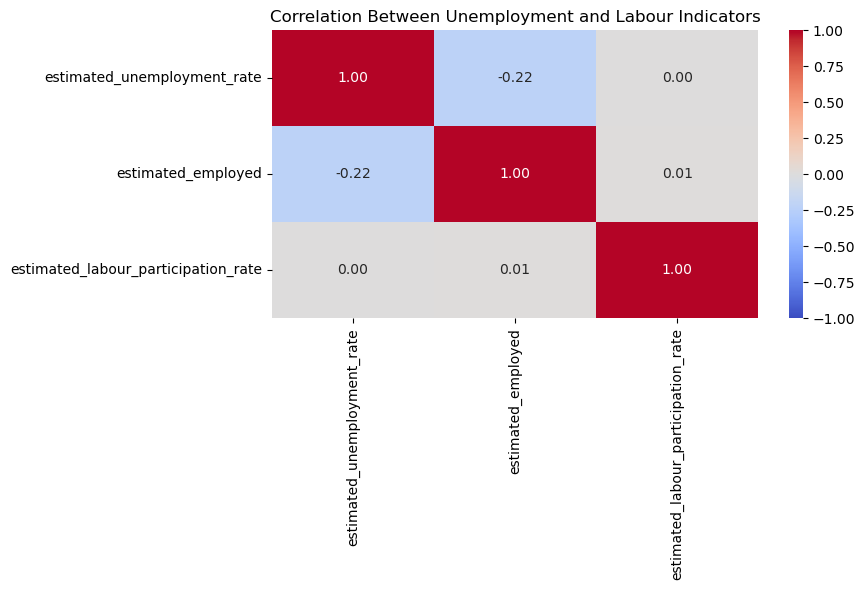

In [28]:

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Unemployment and Labour Indicators")
plt.tight_layout()
plt.show()


In [30]:

analysis_df["period"] = np.where(
    analysis_df["date"] < pd.Timestamp("2020-03-01"),
    "Pre-COVID",
    "Post-COVID"
)

period_avg = (
    analysis_df.groupby("period")["estimated_unemployment_rate"]
    .mean()
    .reindex(["Pre-COVID", "Post-COVID"])
)

display(period_avg.round(2))


period
Pre-COVID      9.51
Post-COVID    17.77
Name: estimated_unemployment_rate, dtype: float64

### Interpretation – top 10 regions
Use the displayed table and chart to name the highest-rate region and compare the top few values. These are averages over the full date range in the cleaned dataset.

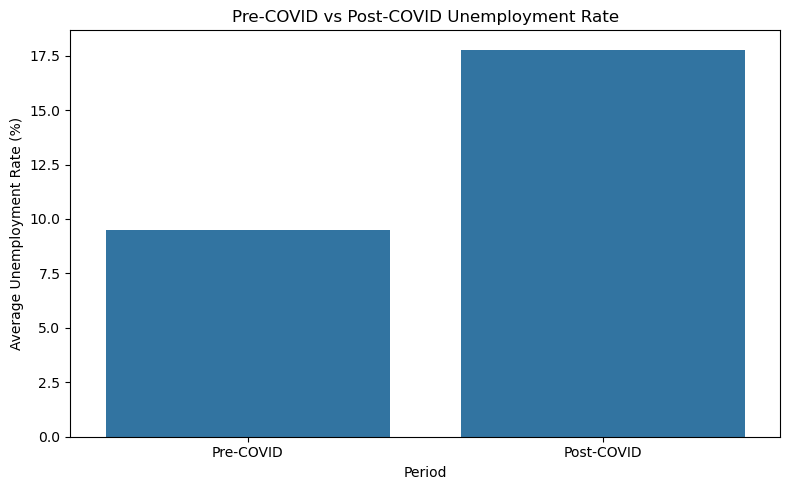

Difference: 8.26 percentage points


In [31]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=period_avg.index,
    y=period_avg.values
)

plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")

plt.tight_layout()
plt.show()

print(
    "Difference:",
    round(period_avg["Post-COVID"] - period_avg["Pre-COVID"], 2),
    "percentage points"
)


## 10. Correlation among labour indicators
The dataset contains an estimated employed **count**, not an employment rate. The heatmap therefore uses the employed count and labour participation rate.

In [ ]:
# Generate a concise summary from the calculated results.
highest_region = region_avg.idxmax()
lowest_region = region_avg.idxmin()
highest_region_rate = region_avg.max()
lowest_region_rate = region_avg.min()

highest_month = monthly_avg.idxmax()
lowest_month = monthly_avg.idxmin()

print("KEY FINDINGS")
print("-" * 50)
print(f"Highest average unemployment region: {highest_region} ({highest_region_rate:.2f}%)")
print(f"Lowest average unemployment region: {lowest_region} ({lowest_region_rate:.2f}%)")
print(f"Highest monthly average: {highest_month:%B %Y} ({monthly_avg.max():.2f}%)")
print(f"Lowest monthly average: {lowest_month:%B %Y} ({monthly_avg.min():.2f}%)")
print(f"Pre-COVID average: {period_avg['Pre-COVID']:.2f}%")
print(f"Post-COVID average: {period_avg['Post-COVID']:.2f}%")
print(f"Post minus pre difference: {difference:.2f} percentage points")

print("\nConclusion:")
print(
    "The analysis describes regional and monthly variation in unemployment "
    "in the supplied India dataset. The pre/post-COVID comparison shows a "
    "difference between the two periods, but it does not by itself establish "
    "that COVID-19 caused that difference."
)